# Naive Bayes phân loại nấm ăn được và nấm độc

Bộ dữ liệu Mushroom có các thuộc tính phân loại và nhãn `class` (`e`: ăn được, `p`: độc). Dùng Categorical Naive Bayes với mã hóa hạng mục được fit trên tập huấn luyện.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report, ConfusionMatrixDisplay)

DATA_PATH = Path("../data/mushrooms.csv")
df = pd.read_csv(DATA_PATH)
print(f"Kích thước dữ liệu: {df.shape}")
display(df.head())
print("\nKiểu dữ liệu và giá trị thiếu:")
display(pd.DataFrame({"kiểu dữ liệu": df.dtypes.astype(str), "giá trị thiếu": df.isna().sum()}))


Kích thước dữ liệu: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g



Kiểu dữ liệu và giá trị thiếu:


,kiểu dữ liệu,giá trị thiếu
class,str,0
cap-shape,str,0
cap-surface,str,0
cap-color,str,0
bruises,str,0
odor,str,0
gill-attachment,str,0
gill-spacing,str,0
gill-size,str,0
gill-color,str,0


## Khám phá dữ liệu và chia tập

In [2]:
TARGET = "class"
print("Phân bố nhãn:")
display(df[TARGET].value_counts(dropna=False).rename(index={"e": "ăn được (e)", "p": "độc (p)"}).to_frame("số lượng"))
df_model = df.dropna(subset=[TARGET]).copy()
X = df_model.drop(columns=[TARGET]).astype("string")
y = df_model[TARGET].astype(str)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)


Phân bố nhãn:


,số lượng
class,
ăn được (e),4208
độc (p),3916


Train: (6499, 22) Test: (1625, 22)


## Mã hóa thuộc tính và huấn luyện Categorical Naive Bayes

OrdinalEncoder ánh xạ từng thuộc tính phân loại sang mã số hạng mục, sau đó CategoricalNB ước lượng xác suất mỗi giá trị theo lớp.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import CategoricalNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
categorical_features = X.columns.tolist()
preprocessor = ColumnTransformer([("categorical", Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
]), categorical_features)])
model = Pipeline([("preprocess", preprocessor), ("classifier", CategoricalNB())])
model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U1](2,)","['e','p']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['cap-shape','cap-surface','cap-color',...,'spore-print-color', 'population','habitat']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passt

## Đánh giá mô hình

Dữ liệu kiểm tra được giữ riêng khỏi quá trình huấn luyện. Báo cáo precision, recall, F1 và ma trận nhầm lẫn cho từng lớp.

Accuracy: 0.9458

Classification report:
              precision    recall  f1-score   support

           e       0.91      0.99      0.95       842
           p       0.99      0.90      0.94       783

    accuracy                           0.95      1625
   macro avg       0.95      0.94      0.95      1625
weighted avg       0.95      0.95      0.95      1625



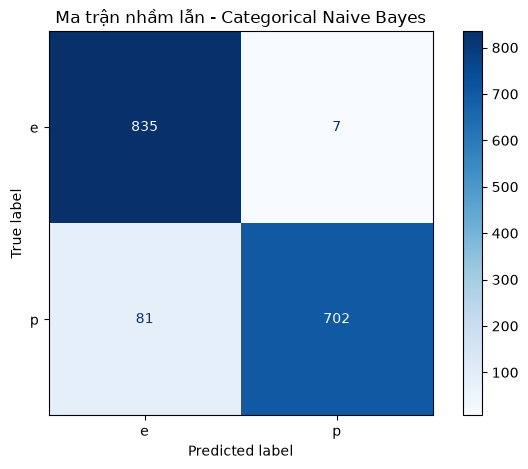

In [4]:
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", values_format="d")
plt.title("Ma trận nhầm lẫn - Categorical Naive Bayes")
plt.tight_layout()
plt.show()


## Nhận xét

Dựa trên classification report và ma trận nhầm lẫn ở trên, hãy nhận xét mô hình phân loại **class (e/p)** tốt đến đâu, đặc biệt chú ý lớp ít xuất hiện và các trường hợp dự đoán sai.